<a href="https://colab.research.google.com/github/JZ2034/46000-HW4-Data-Set/blob/main/46000_HW4_Data_Set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import os
import glob
import re
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

# Look for the CSV; if it isn't here, open an upload dialog
matches = glob.glob("*FIFA*21*.csv") + glob.glob("*fifa*21*.csv")
if not matches:
    from google.colab import files
    print("CSV not found. Choose FIFA-21_Complete.csv in the dialog below...")
    uploaded = files.upload()
    matches = list(uploaded.keys())

CSV_PATH = matches[0]
print("Using file:", CSV_PATH)

df = pd.read_csv(CSV_PATH, sep=";", encoding="utf-8-sig")
df.columns = [c.strip().lower() for c in df.columns]
print(df.shape)
df.head()

Using file: FIFA-21 Complete.csv
(17981, 9)


,player_id,name,nationality,position,overall,age,hits,potential,team
0,158023,Lionel Messi,Argentina,ST|CF|RW,94,33,299,94,FC Barcelona
1,20801,Cristiano Ronaldo,Portugal,ST|LW,93,35,276,93,Juventus
2,190871,Neymar Jr,Brazil,CAM|LW,92,28,186,92,Paris Saint-Germain
3,203376,Virgil van Dijk,Netherlands,CB,91,29,127,92,Liverpool
4,200389,Jan Oblak,Slovenia,GK,91,27,47,93,Atlético Madrid


# Exploratory Data Analysis: FIFA 2021 Complete Player Data

**Source:** Kaggle, `aayushmishra1512/fifa-2021-complete-player-data`

Following the NIST/SEMATECH Engineering Statistics Handbook (EDA chapter), this notebook:
1. Checks the dataset against the assignment requirements
2. Looks at each variable on its own (histograms, bar charts, summary statistics, outliers)
3. Compares all numerical variables side by side (standardized box plot)
4. Looks at pairwise relationships: numeric vs numeric, categorical vs categorical, and categorical vs numeric

In [38]:
# ---- Clean text columns ----
df["team"] = df["team"].str.strip()
df["position"] = df["position"].str.strip()

# ---- Derived columns ----
# Primary position = first listed (e.g. "ST|CF|RW" -> "ST")
df["primary_position"] = df["position"].str.split("|").str[0]

def pos_group(p):
    if p == "GK": return "Goalkeeper"
    if p in ["CB", "LB", "RB", "LWB", "RWB"]: return "Defender"
    if p in ["CDM", "CM", "CAM", "LM", "RM"]: return "Midfielder"
    return "Forward"
df["position_group"] = df["primary_position"].map(pos_group)

# Two extra numeric variables built from the existing columns
df["potential_gap"] = df["potential"] - df["overall"]          # room to grow
df["n_positions"] = df["position"].str.count(r"\|") + 1        # versatility

# ---- Variable lists ----
# player_id and name are identifiers, so they are left out of the analysis
num_cols = ["overall", "age", "potential", "hits", "potential_gap", "n_positions"]
cat_cols = ["position_group", "primary_position", "nationality", "team"]

print("Rows:", len(df), "| Columns:", df.shape[1])
print("Numerical variables used:", num_cols)
print("Categorical variables used:", cat_cols)
print("\nRequirement check:")
print("  >= 30 rows       :", len(df) >= 30)
print("  >= 8 columns     :", df.shape[1] >= 8)
print("  >= 5 numerical   :", len(num_cols) >= 5)
df[num_cols + cat_cols].info()

Rows: 17981 | Columns: 13
Numerical variables used: ['overall', 'age', 'potential', 'hits', 'potential_gap', 'n_positions']
Categorical variables used: ['position_group', 'primary_position', 'nationality', 'team']

Requirement check:
  >= 30 rows       : True
  >= 8 columns     : True
  >= 5 numerical   : True
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17981 entries, 0 to 17980
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   overall           17981 non-null  int64 
 1   age               17981 non-null  int64 
 2   potential         17981 non-null  int64 
 3   hits              17981 non-null  int64 
 4   potential_gap     17981 non-null  int64 
 5   n_positions       17981 non-null  int64 
 6   position_group    17981 non-null  object
 7   primary_position  17981 non-null  object
 8   nationality       17981 non-null  object
 9   team              17981 non-null  object
dtypes: int64(6), object(4)

In [39]:
def outlier_info(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < lo) | (s > hi)]
    return pd.Series({"min": s.min(), "max": s.max(), "mean": s.mean(),
                      "median": s.median(), "std": s.std(),
                      "lower_fence": lo, "upper_fence": hi,
                      "n_outliers": len(out),
                      "pct_outliers": 100 * len(out) / len(s)})

summary = df[num_cols].apply(outlier_info).T
display(summary.round(2))
print("Missing values per variable:")
display(df[num_cols + cat_cols].isna().sum().to_frame("missing"))

,min,max,mean,median,std,lower_fence,upper_fence,n_outliers,pct_outliers
overall,56.0,94.0,67.27,67.0,5.92,51.0,83.0,156.0,0.87
age,17.0,43.0,26.31,26.0,4.56,12.5,40.5,15.0,0.08
potential,57.0,95.0,71.74,71.0,5.96,53.5,89.5,45.0,0.25
hits,0.0,371.0,2.69,0.0,10.85,-3.0,5.0,1617.0,8.99
potential_gap,0.0,25.0,4.46,3.0,5.05,-12.0,20.0,49.0,0.27
n_positions,1.0,5.0,1.68,2.0,0.78,-0.5,3.5,250.0,1.39


Missing values per variable:


,missing
overall,0
age,0
potential,0
hits,0
potential_gap,0
n_positions,0
position_group,0
primary_position,0
nationality,0
team,0


## 1. One-dimensional views of each variable

For every numerical variable: a histogram (with a KDE curve), plus the min, max, mean, median, and IQR-based outliers. For categorical variables: bar charts.

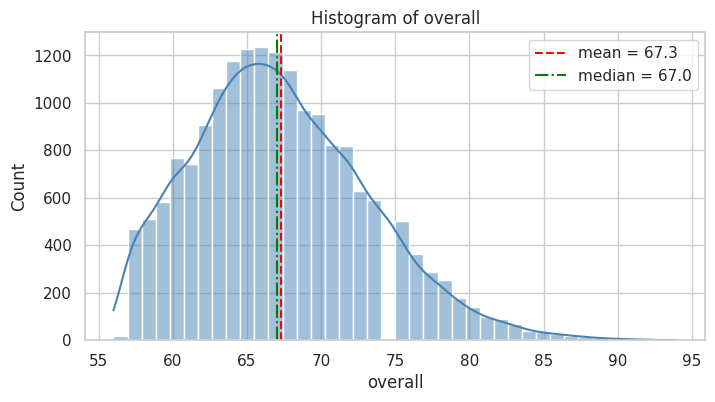

**overall**: min = 56.00, max = 94.00, mean = 67.27, median = 67.00. Distribution is right-skewed (skew = 0.52). 156 outliers (0.9%) fall outside [51.00, 83.00].



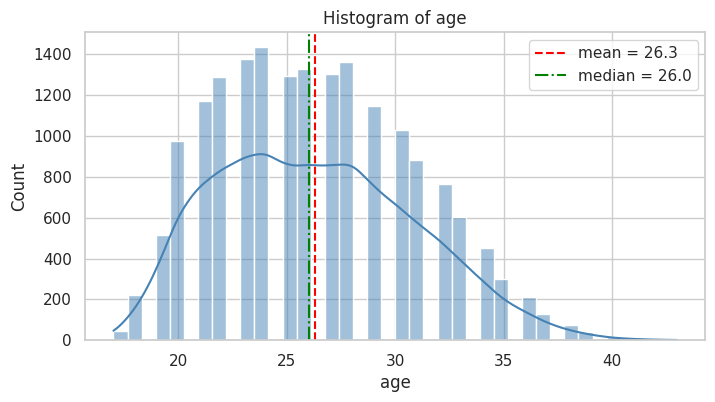

**age**: min = 17.00, max = 43.00, mean = 26.31, median = 26.00. Distribution is roughly symmetric (skew = 0.35). 15 outliers (0.1%) fall outside [12.50, 40.50].



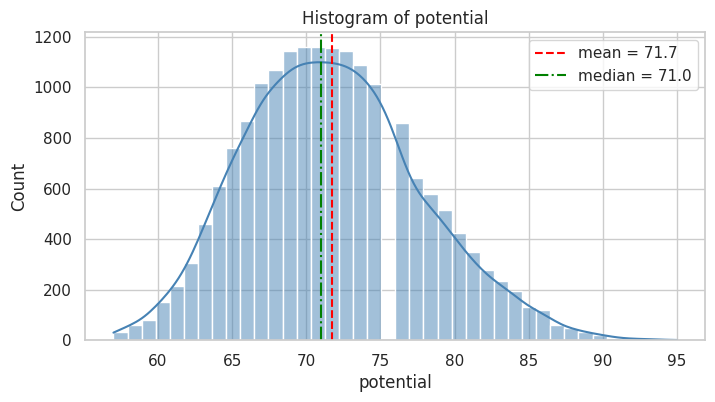

**potential**: min = 57.00, max = 95.00, mean = 71.74, median = 71.00. Distribution is roughly symmetric (skew = 0.32). 45 outliers (0.3%) fall outside [53.50, 89.50].



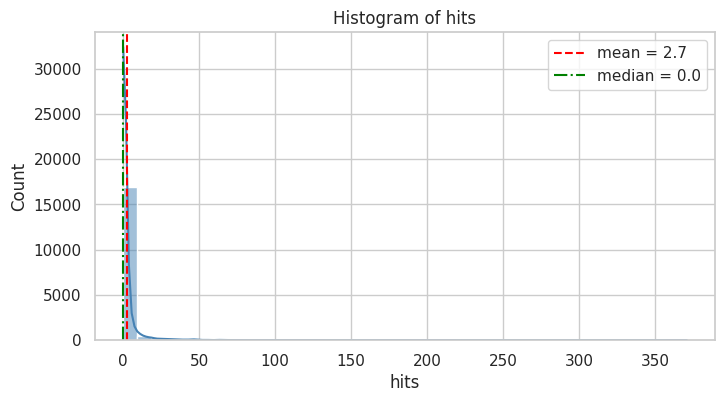

**hits**: min = 0.00, max = 371.00, mean = 2.69, median = 0.00. Distribution is right-skewed (skew = 13.02). 1617 outliers (9.0%) fall outside [-3.00, 5.00].



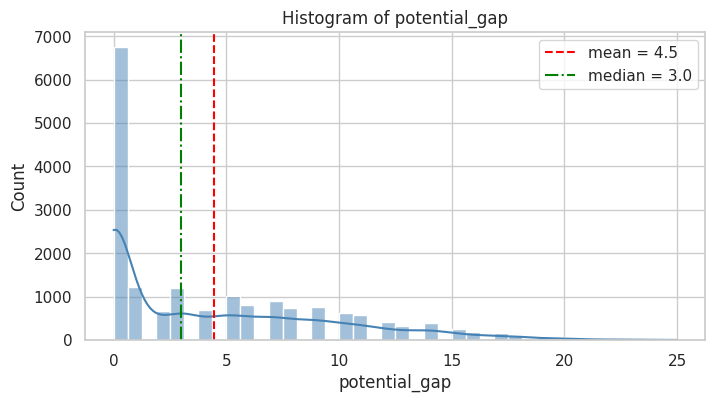

**potential_gap**: min = 0.00, max = 25.00, mean = 4.46, median = 3.00. Distribution is right-skewed (skew = 1.00). 49 outliers (0.3%) fall outside [-12.00, 20.00].



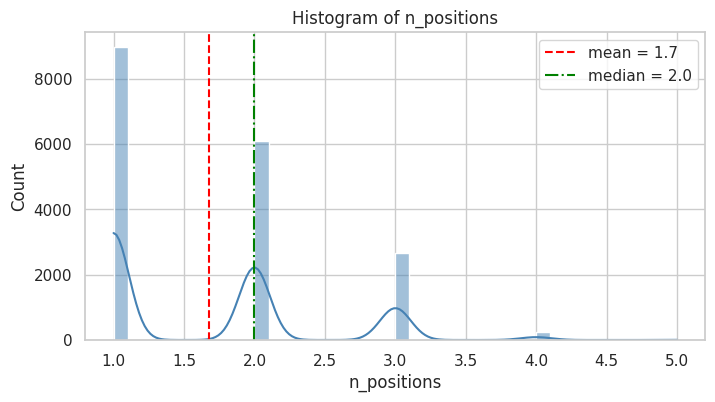

**n_positions**: min = 1.00, max = 5.00, mean = 1.68, median = 2.00. Distribution is right-skewed (skew = 0.83). 250 outliers (1.4%) fall outside [-0.50, 3.50].



In [40]:
for c in num_cols:
    s = df[c].dropna()
    info = outlier_info(s)
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(s, bins=40, kde=True, ax=ax, color="steelblue")
    ax.axvline(info["mean"], color="red", ls="--", label=f"mean = {info['mean']:,.1f}")
    ax.axvline(info["median"], color="green", ls="-.", label=f"median = {info['median']:,.1f}")
    ax.set_title(f"Histogram of {c}")
    ax.legend()
    plt.show()

    skew = s.skew()
    shape = ("right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "roughly symmetric")
    print(f"**{c}**: min = {info['min']:,.2f}, max = {info['max']:,.2f}, "
          f"mean = {info['mean']:,.2f}, median = {info['median']:,.2f}. "
          f"Distribution is {shape} (skew = {skew:.2f}). "
          f"{int(info['n_outliers'])} outliers ({info['pct_outliers']:.1f}%) fall outside "
          f"[{info['lower_fence']:,.2f}, {info['upper_fence']:,.2f}].\n")

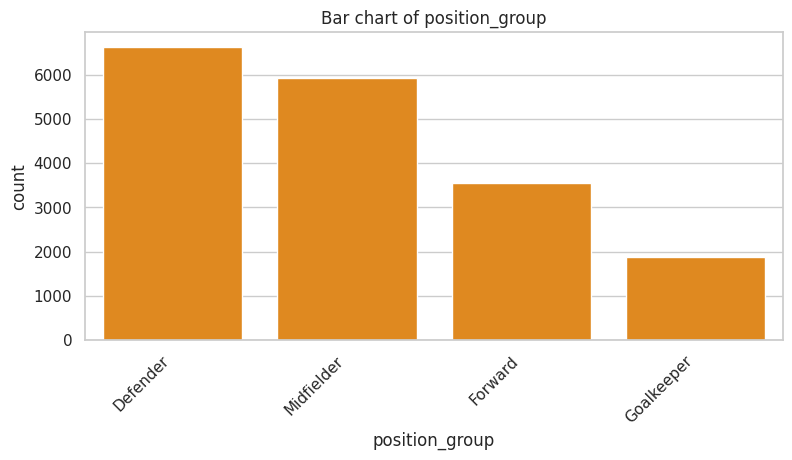

**position_group**: 4 unique values. Most common = 'Defender' (6,625 rows, 36.8%); least common = 'Goalkeeper' (1,885 rows).



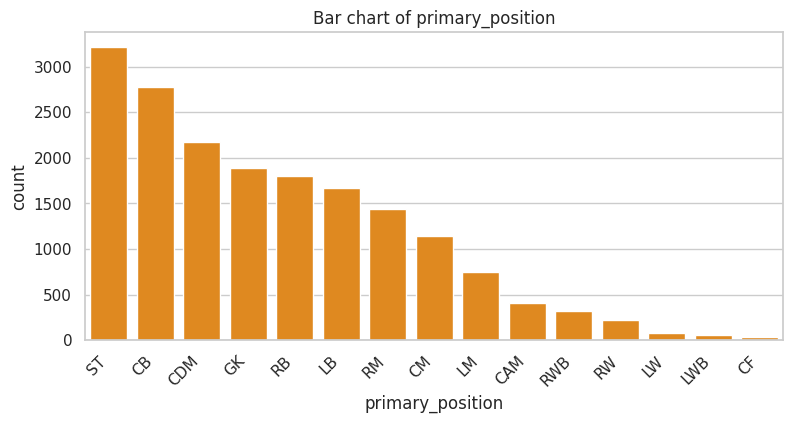

**primary_position**: 15 unique values. Most common = 'ST' (3,216 rows, 17.9%); least common = 'CF' (38 rows).



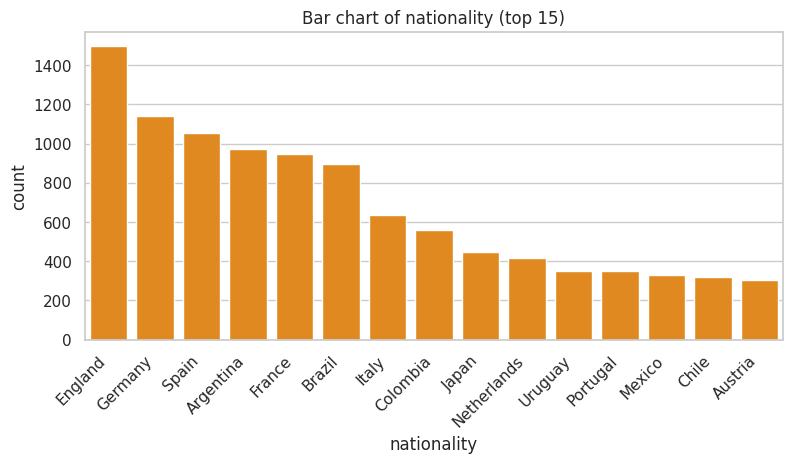

**nationality**: 162 unique values. Most common = 'England' (1,496 rows, 8.3%); least common = 'Nicaragua' (1 rows).



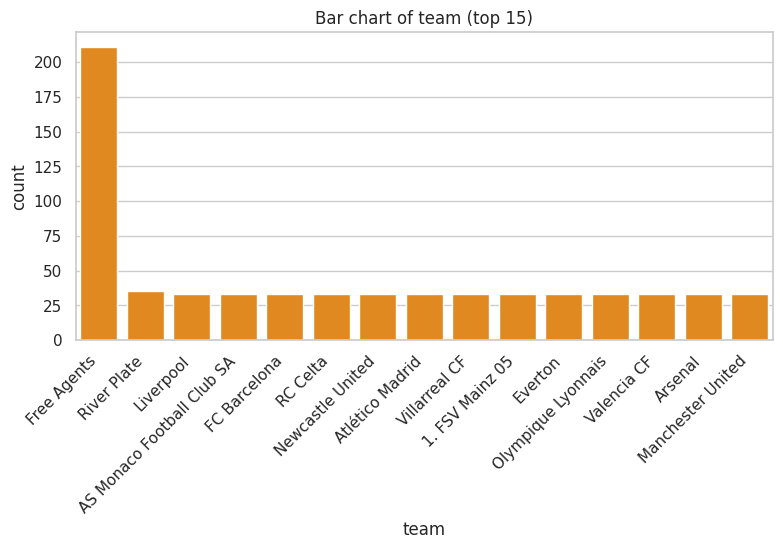

**team**: 713 unique values. Most common = 'Free Agents' (211 rows, 1.2%); least common = 'UCD AFC' (1 rows).



In [41]:
for c in cat_cols:
    vc = df[c].value_counts()
    top = vc.head(15)
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.barplot(x=top.index.astype(str), y=top.values, ax=ax, color="darkorange")
    ax.set_title(f"Bar chart of {c}" + (" (top 15)" if len(vc) > 15 else ""))
    ax.set_ylabel("count")
    plt.xticks(rotation=45, ha="right")
    plt.show()
    print(f"**{c}**: {vc.shape[0]} unique values. Most common = '{vc.index[0]}' "
          f"({vc.iloc[0]:,} rows, {100*vc.iloc[0]/vc.sum():.1f}%); "
          f"least common = '{vc.index[-1]}' ({vc.iloc[-1]:,} rows).\n")

## 2. All numerical variables side by side (single box plot)

The variables are on very different scales (e.g. age in years vs. value in euros), so each is **standardized (z-score)** before plotting. Otherwise the largest-scale variable would flatten all the others. Points beyond the whiskers are outliers under the 1.5 × IQR rule.

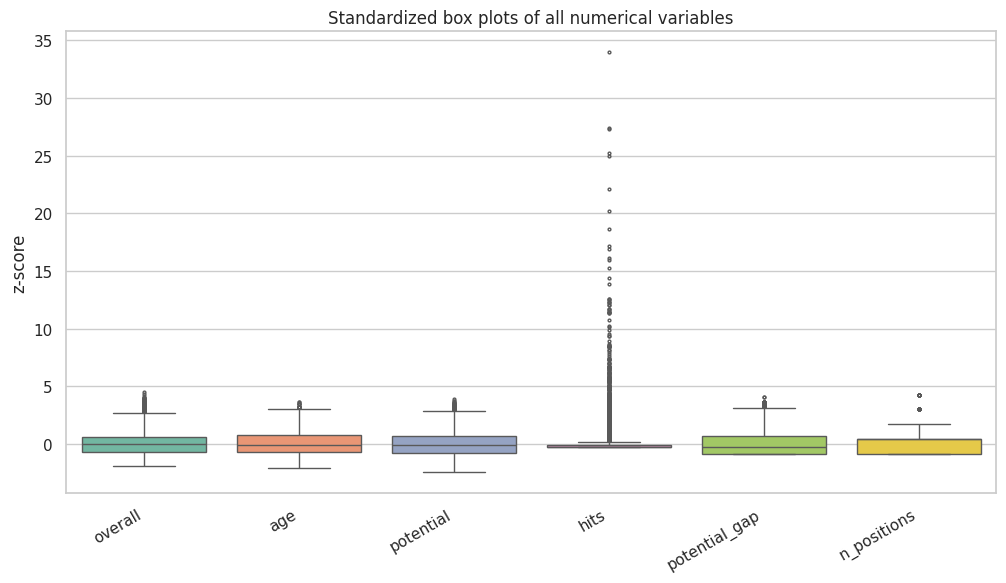

In [42]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=z, ax=ax, orient="v", fliersize=2, palette="Set2")
ax.set_title("Standardized box plots of all numerical variables")
ax.set_ylabel("z-score")
plt.xticks(rotation=30, ha="right")
plt.show()

## 3. Pairwise relationships

### 3a. Numerical vs numerical: scatter plot matrix
Each off-diagonal panel is one scatter plot of a pair of variables, and the diagonal shows each variable's distribution. A random sample keeps it readable and fast.


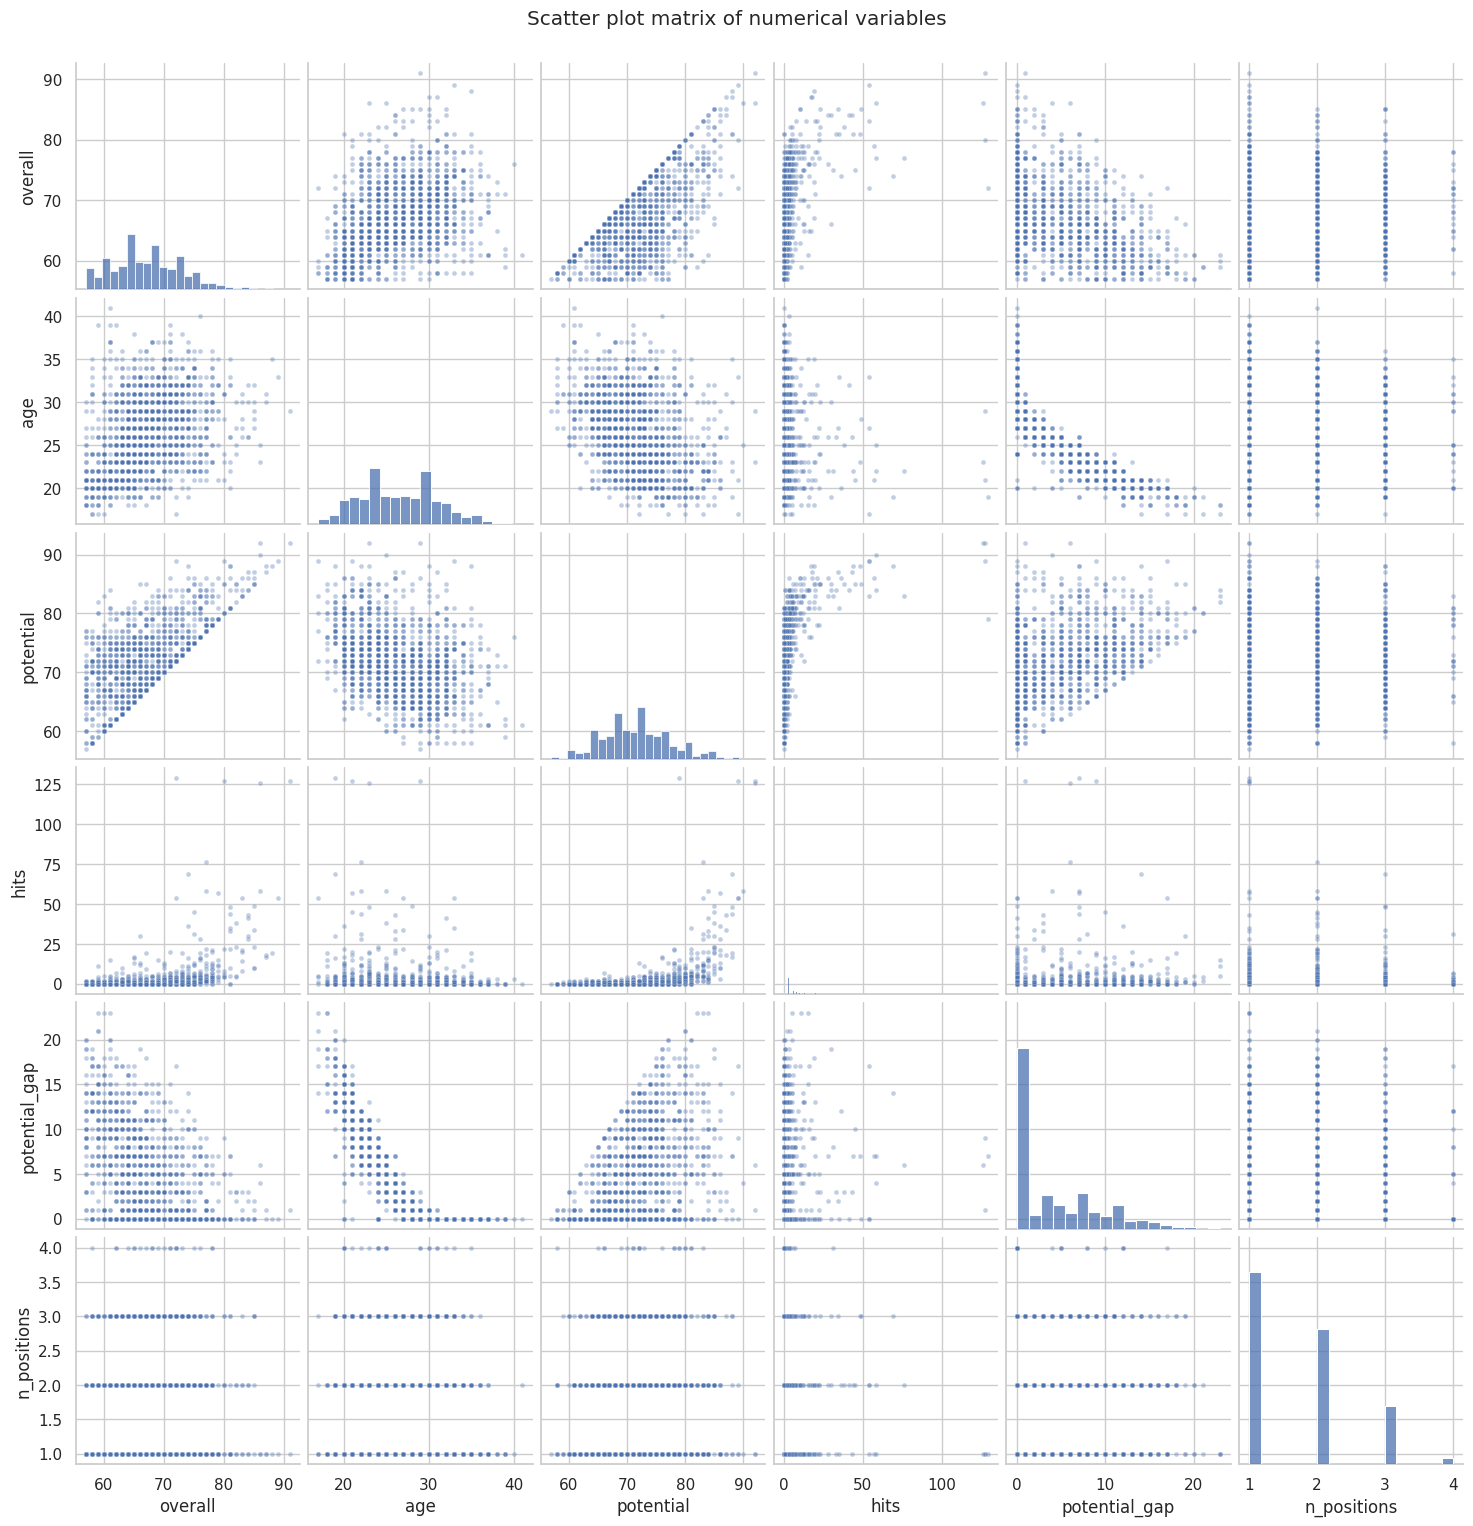

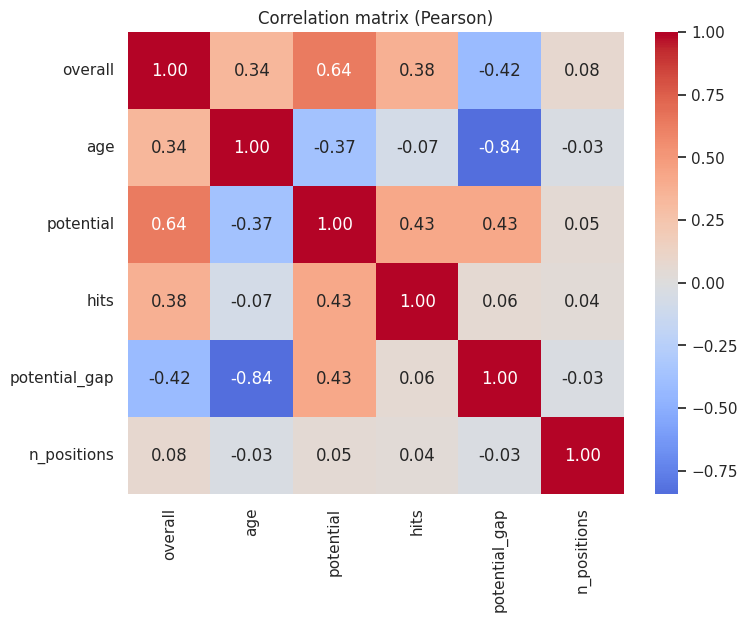

Strongest relationships (|r|):


age        potential_gap    0.843
overall    potential        0.639
potential  potential_gap    0.431
           hits             0.430
overall    potential_gap    0.419
dtype: float64

In [43]:
sample = df[num_cols].dropna().sample(n=min(1500, len(df)), random_state=42)
g = sns.pairplot(sample, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 12})
g.fig.suptitle("Scatter plot matrix of numerical variables", y=1.02)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
plt.show()

corr = df[num_cols].corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("Strongest relationships (|r|):")
display(pairs.head(5).round(3))

### 3b. Categorical vs categorical

Categorical pairs are shown by **aggregating** one variable against another: a cross-tabulation of counts, drawn as a heatmap, and a stacked bar of row percentages.

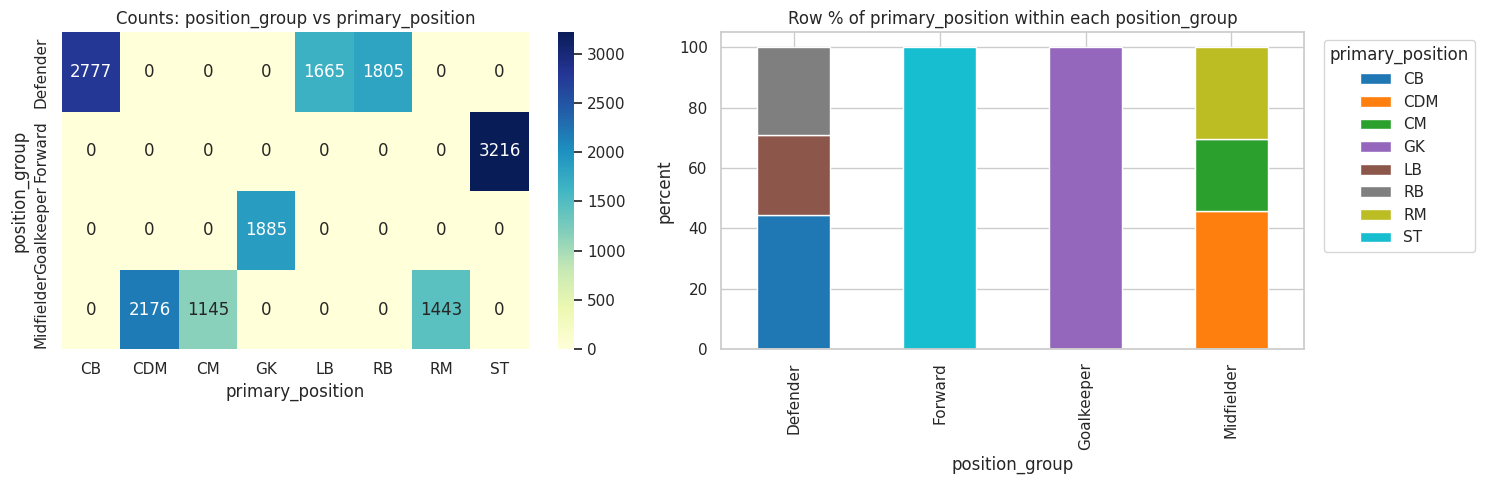

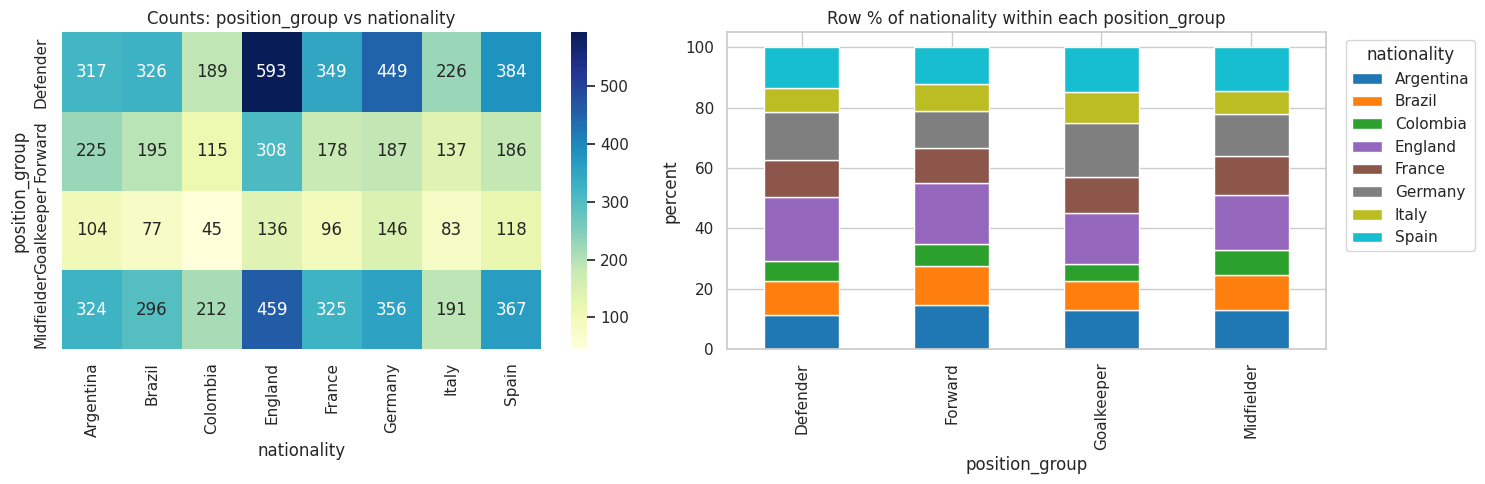

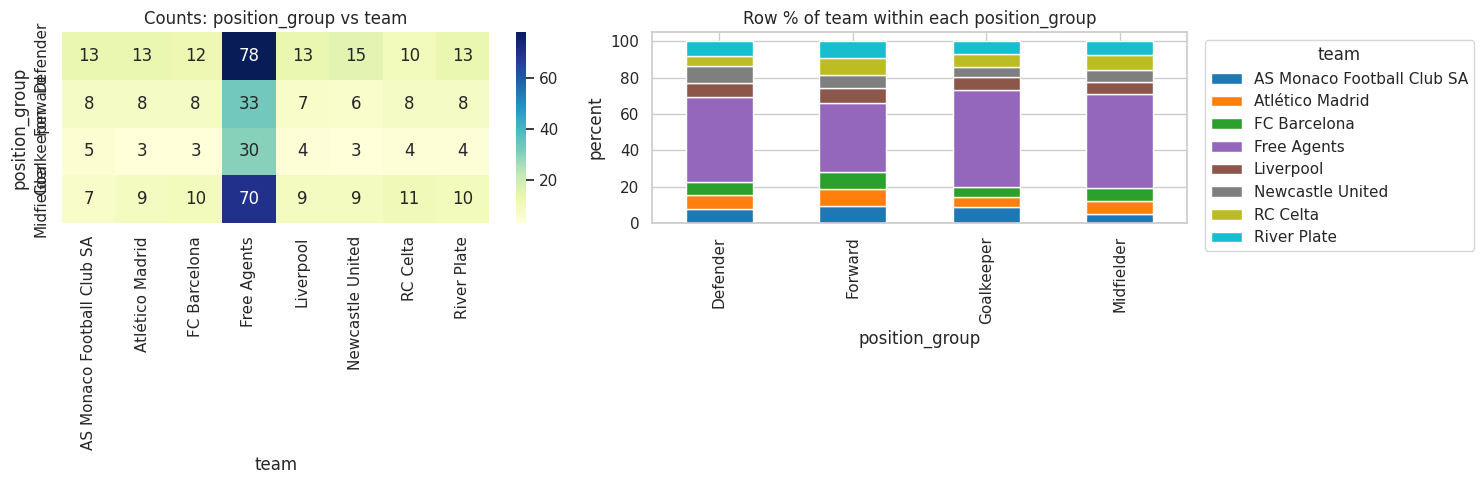

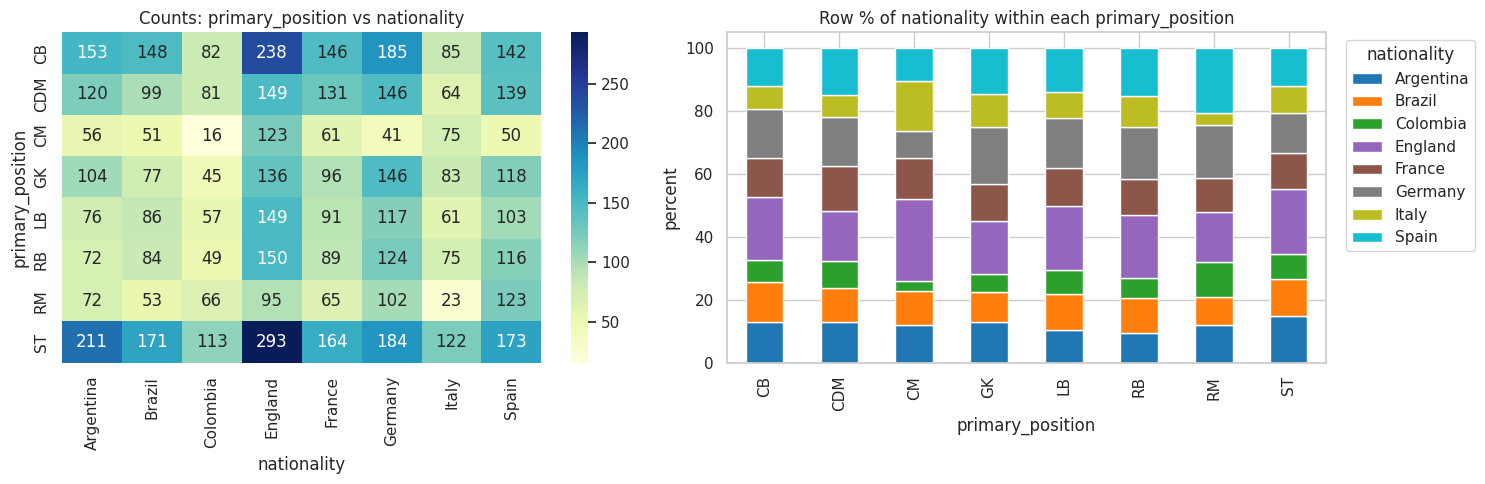

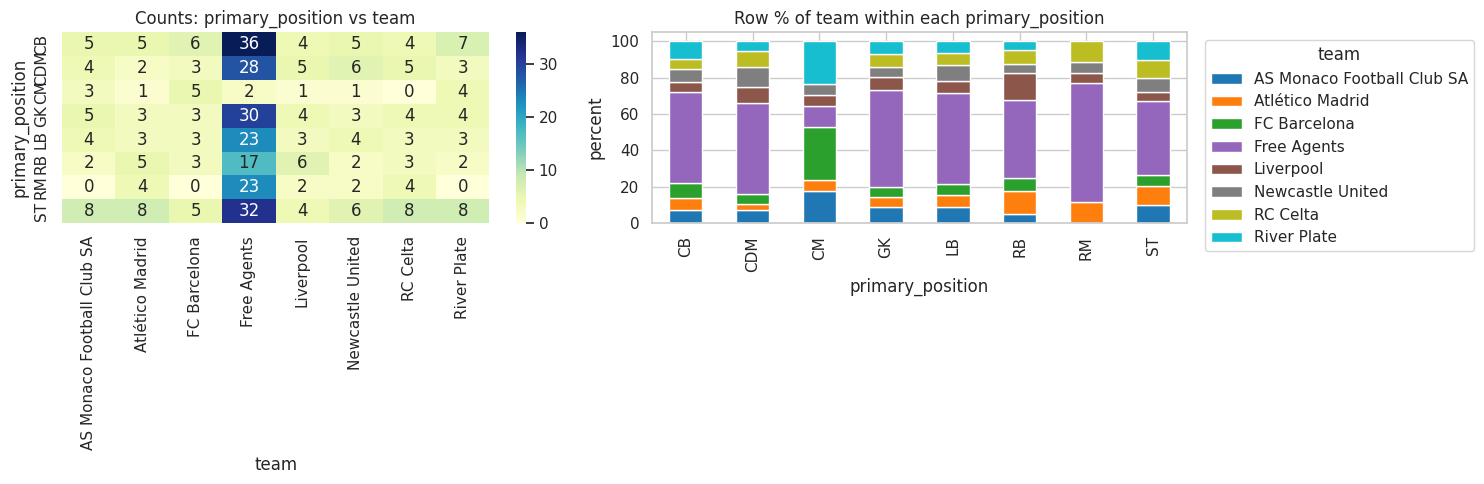

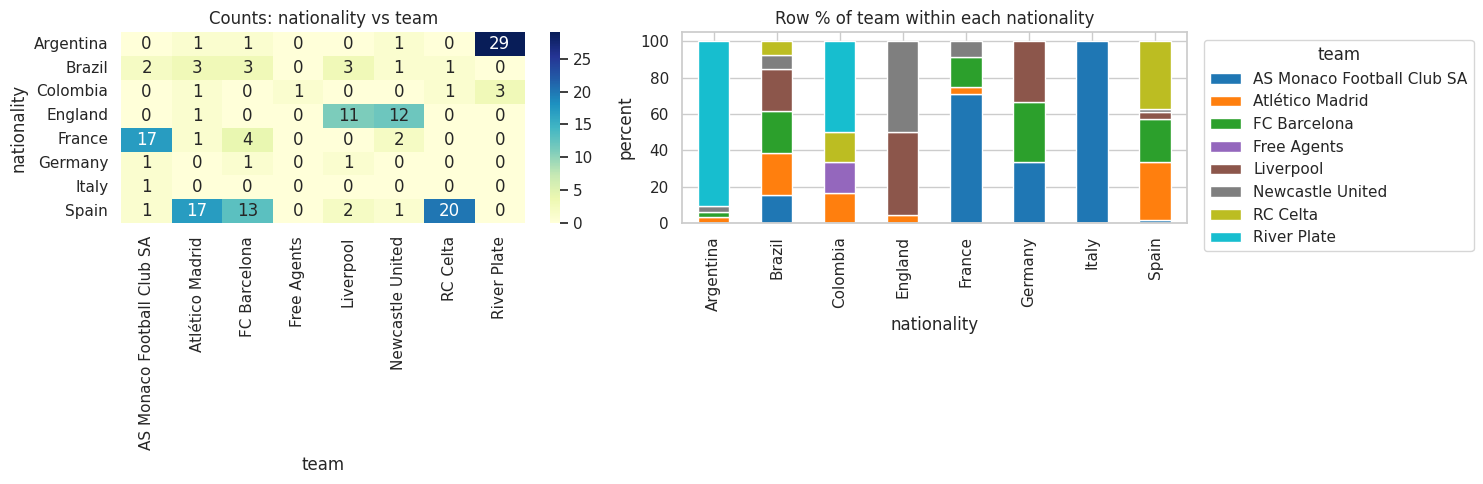

In [44]:
import itertools

# Use low-cardinality versions so the tables stay readable
def reduced(col, k=8):
    top = df[col].value_counts().head(k).index
    return df[col].where(df[col].isin(top))

for a, b in itertools.combinations(cat_cols, 2):
    ct = pd.crosstab(reduced(a), reduced(b))
    pct = ct.div(ct.sum(axis=1), axis=0) * 100

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0])
    axes[0].set_title(f"Counts: {a} vs {b}")
    pct.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10")
    axes[1].set_title(f"Row % of {b} within each {a}")
    axes[1].set_ylabel("percent")
    axes[1].legend(title=b, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

### 3c. Categorical vs numerical

Two views: (1) the numerical variable's distribution **split by category** (box plots), and (2) a scatter plot of two numerical variables with **color** indicating the category.

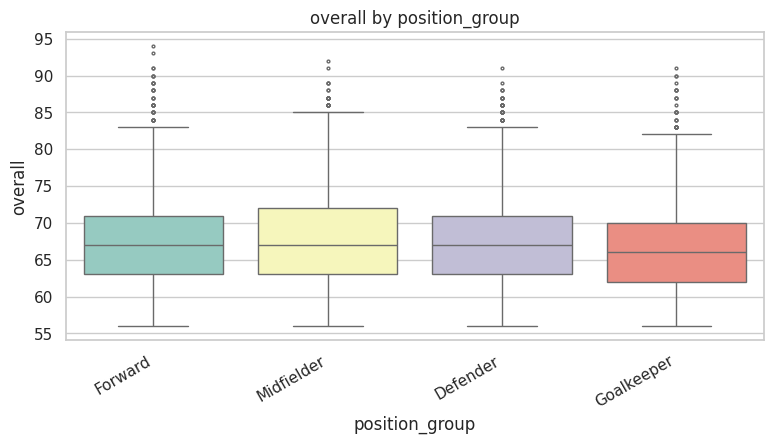

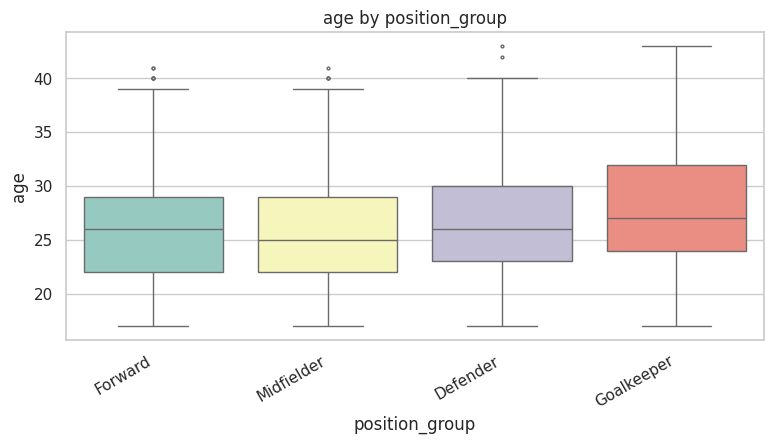

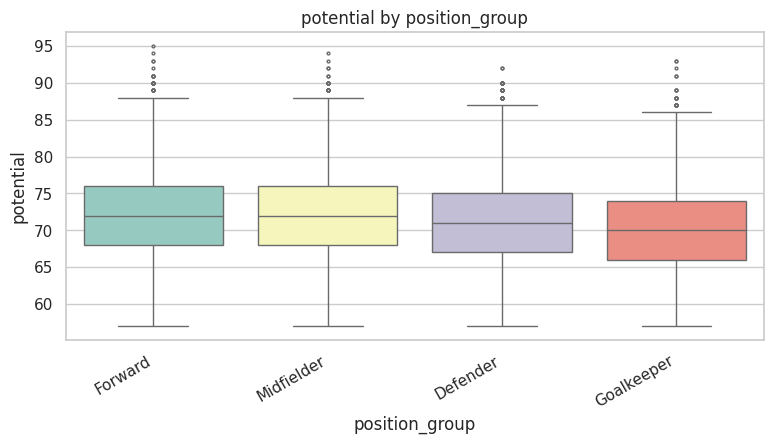

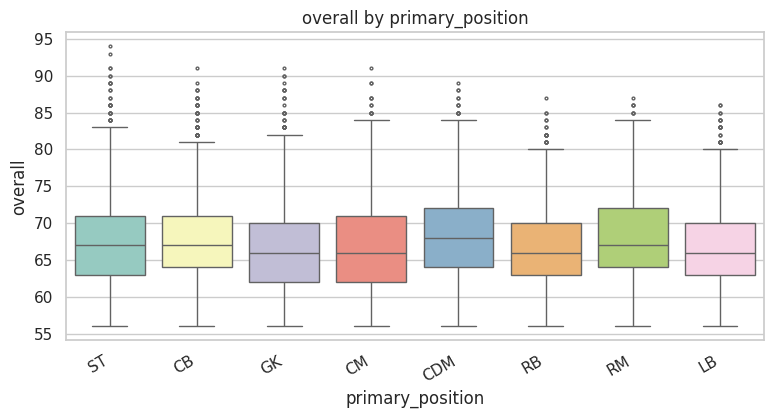

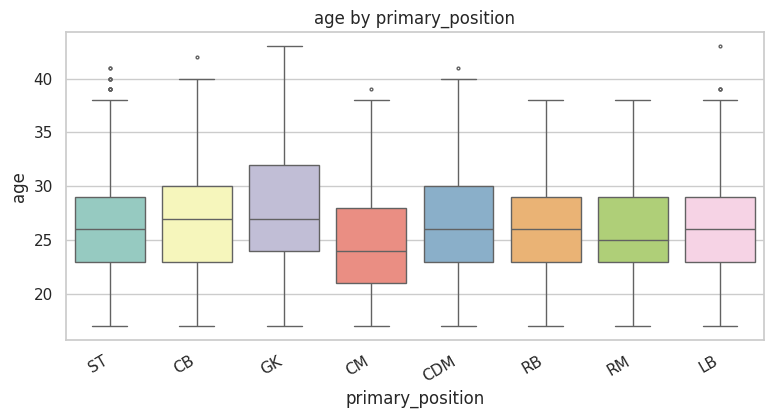

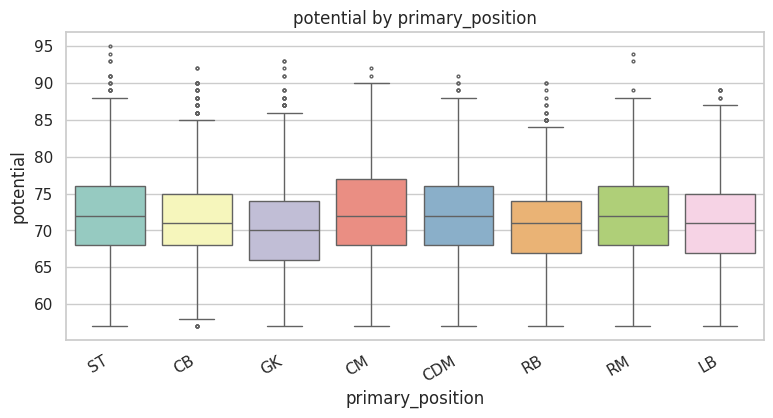

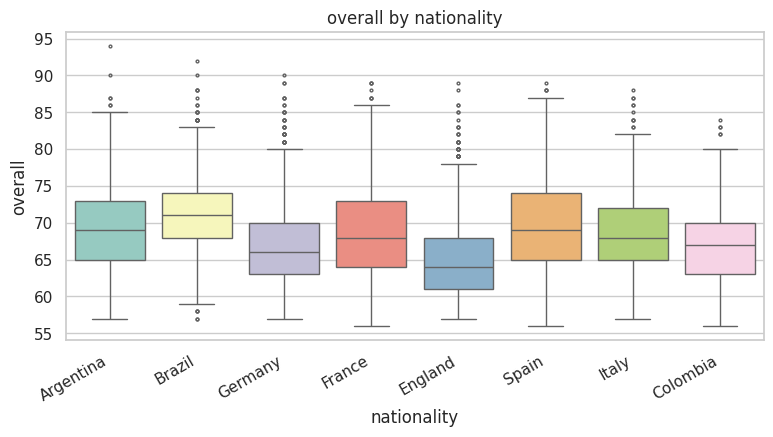

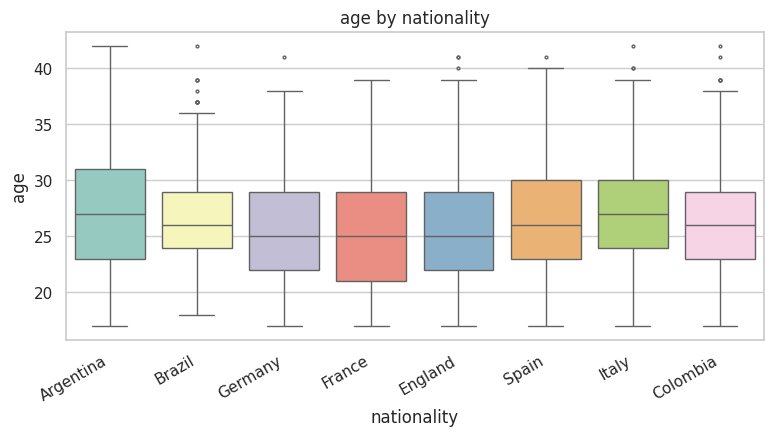

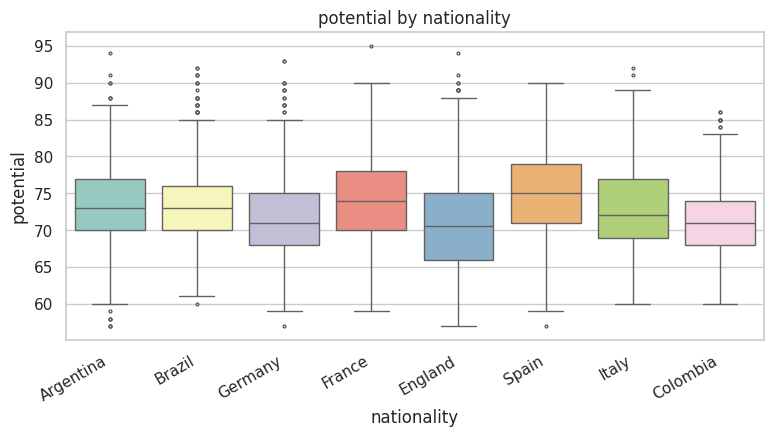

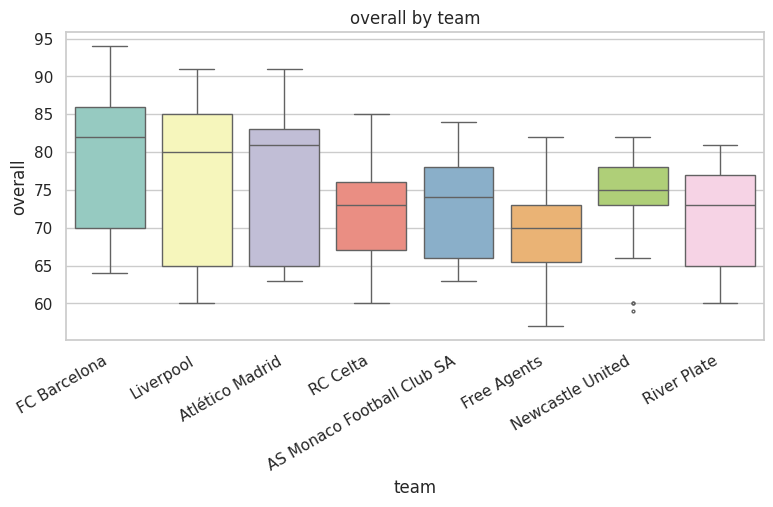

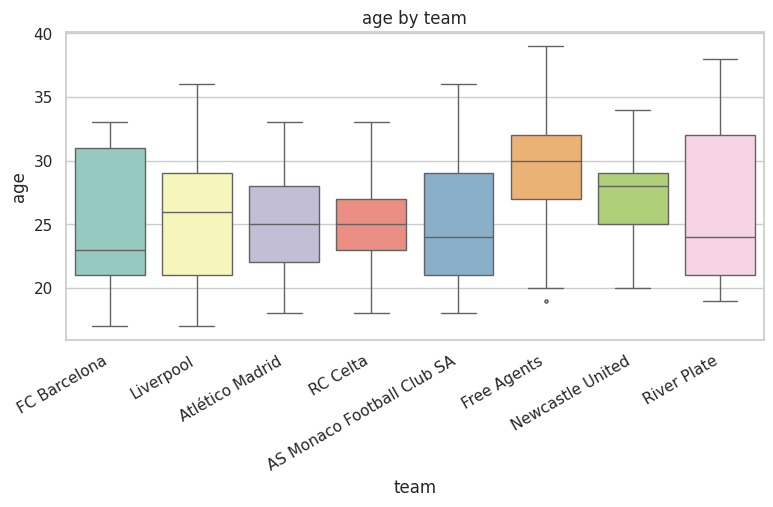

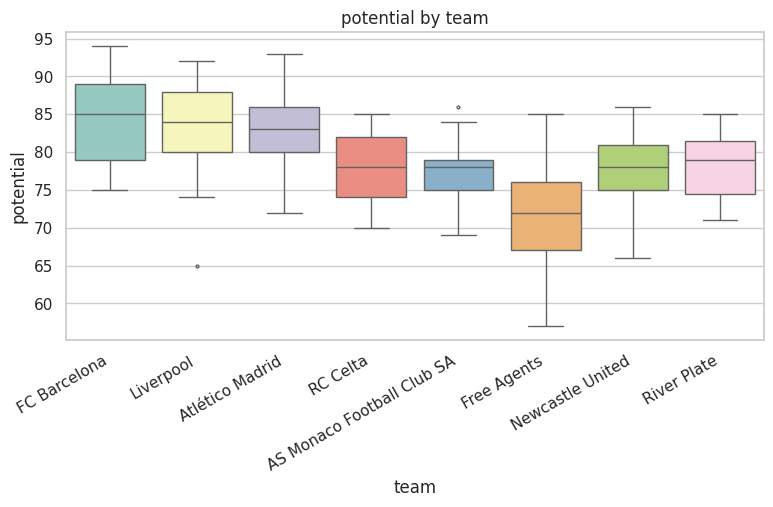

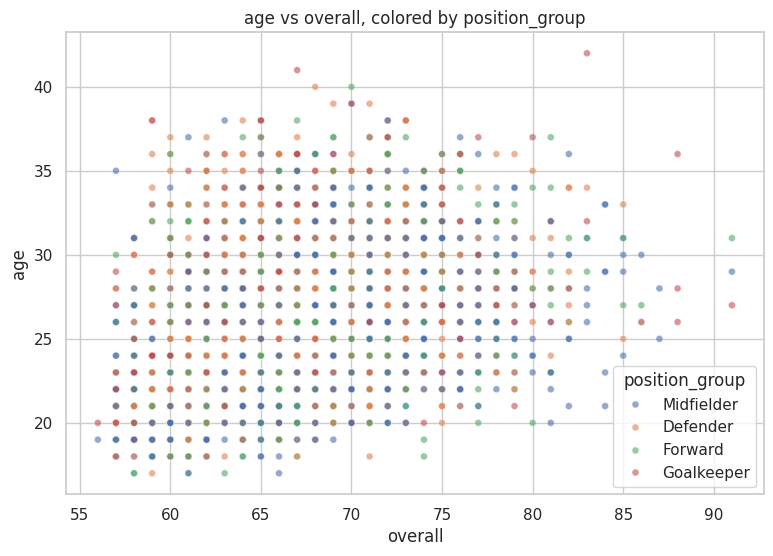

,overall,age,potential,hits,potential_gap,n_positions
position_group,,,,,,
Defender,67.08,26.51,71.31,2.26,4.22,1.68
Forward,67.48,26.03,72.03,3.72,4.56,1.66
Goalkeeper,66.56,27.73,70.68,1.68,4.12,1.00
Midfielder,67.59,25.81,72.38,2.87,4.79,1.91


In [45]:
# (1) Box plots of a numeric variable grouped by each categorical variable
for cat in cat_cols:
    top = df[cat].value_counts().head(8).index
    sub = df[df[cat].isin(top)]
    for num in num_cols[:3]:
        fig, ax = plt.subplots(figsize=(9, 4))
        sns.boxplot(data=sub, x=cat, y=num, ax=ax, palette="Set3", fliersize=2)
        ax.set_title(f"{num} by {cat}")
        plt.xticks(rotation=30, ha="right")
        plt.show()

# (2) Scatter plots colored by a categorical variable
x_var, y_var = num_cols[0], num_cols[1]
hue_var = "position_group" if "position_group" in df.columns else cat_cols[0]
sub = df[[x_var, y_var, hue_var]].dropna()
sub = sub[sub[hue_var].isin(sub[hue_var].value_counts().head(6).index)]
sub = sub.sample(n=min(3000, len(sub)), random_state=1)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=sub, x=x_var, y=y_var, hue=hue_var, alpha=0.6, s=25, ax=ax)
ax.set_title(f"{y_var} vs {x_var}, colored by {hue_var}")
plt.show()

# Group means as a compact numeric summary
display(df.groupby(hue_var)[num_cols].mean().round(2))

## 4. Conclusions

*(Fill in after running; examples of what to comment on)*

- **Distributions:** which variables are skewed (wage and value are typically heavily right-skewed), and which are roughly symmetric (age, overall rating).
- **Outliers:** which variables have the most outliers and whether they are errors or real (e.g., a handful of superstar players with enormous wages and values).
- **Numerical relationships:** the strongest correlations from the heatmap (e.g., overall rating vs. potential, overall rating vs. value or wage) and any non-linear shapes in the scatter matrix.
- **Categorical vs categorical:** how position groups relate to preferred foot, body type, etc.
- **Categorical vs numerical:** how numeric variables such as height, weight, and sprint speed differ across position groups. Goalkeepers and defenders typically differ from forwards.
- **Data quality:** missing values and any variables that needed cleaning (value, wage, and height are often stored as text).